# Tutorial 01

This is the notebook to walk through in class. Run the cells from top to bottom. Later cells use names created above.

`Shift+Enter` runs the current cell. If the kernel restarts, run again from the top.


## Open this notebook

- **Colab.** Replace `github.com` with `githubtocolab.com` in the repository URL, then open this file. Run the setup cell so Colab can see `detector_data.csv`.
- **On your own computer.** Install Anaconda first. The click-by-click steps are in the Software Tutorials. Open this file from the `01 Practices of python language` folder, so the CSV sits beside the notebook.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "01 Practices of python language"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    os.chdir(repo / LESSON_DIR)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/01 Practices of python language


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, and Matplotlib draws figures.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After it finishes, restart the kernel and run the cells above again.


In [3]:
%pip install numpy pandas matplotlib


Note: you may need to restart the kernel to use updated packages.


## Variables and types

A name points to a value. Read the type printed beside each value.


In [4]:
speed = 28
detector = "A"
congested = speed < 30

print(speed, type(speed))
print(detector, type(detector))
print(congested, type(congested))


28 <class 'int'>
A <class 'str'>
True <class 'bool'>


## Lists

The first position is `0`. The last position is `-1`.


In [5]:
speeds = [62, 28, 18, 70, 45, 33, 22, 15]

print(len(speeds))
print(speeds[0])
print(speeds[-1])


8
62
15


## Dictionaries and tuples

A dictionary reads one field by name. A tuple keeps those fields in order.


In [6]:
record = {"detector": "A", "hour": 8, "speed": 28, "flow": 1600}
fixed = (record["detector"], record["hour"], record["speed"])

print(record["speed"])
print(fixed)


28
('A', 8, 28)


## Loop, condition, and a set

`records` is a small table written in the notebook. The loop counts speeds below 30. The set keeps each detector name once. The count is 4.

This short list is only for the loop. The CSV below is the real set of measurements, and flow there is not a straight line in speed or in density.


In [7]:
records = [
    {"detector": "A", "hour": 7, "speed": 62, "flow": 800},
    {"detector": "A", "hour": 8, "speed": 28, "flow": 1600},
    {"detector": "A", "hour": 9, "speed": 18, "flow": 1400},
    {"detector": "B", "hour": 7, "speed": 70, "flow": 500},
    {"detector": "B", "hour": 8, "speed": 45, "flow": 1200},
    {"detector": "B", "hour": 9, "speed": 33, "flow": 1500},
    {"detector": "C", "hour": 8, "speed": 22, "flow": 900},
    {"detector": "C", "hour": 9, "speed": 15, "flow": 700},
]

congested_count = 0
detectors = set()
for one in records:
    detectors.add(one["detector"])
    if one["speed"] < 30:
        congested_count = congested_count + 1

print(congested_count)
print(detectors)


4
{'B', 'A', 'C'}


## while and break

Stop at the first speed below 30. That record is detector A at hour 8.


In [8]:
i = 0
while i < len(records):
    if records[i]["speed"] < 30:
        print(records[i]["detector"], records[i]["hour"], records[i]["speed"])
        break
    i = i + 1


A 8 28


## A function

`mean` receives a list and returns one number. The result for `speeds` is 36.625.


In [9]:
def mean(values):
    return sum(values) / len(values)

print(mean(speeds))


36.625


## NumPy

`shape` is `(8,)`. The slice is the first three speeds. The condition keeps speeds below 30.


In [10]:
speeds_np = np.array(speeds)

print(speeds_np.shape)
print(speeds_np[:3])
print(speeds_np[speeds_np < 30])
print(speeds_np.mean())


(8,)
[62 28 18]
[28 18 22 15]
36.625


## Read a CSV file

`detector_data.csv` uses the measurements from `FD_data.csv` in the regression lesson. `density` is `k` and `flow` is `q`. `speed` is flow divided by density. There are 42 records.

Flow rises as density increases, then falls. It is not a straight line in density, and it is not a straight line in speed.

`read_csv` builds a DataFrame. `shape` is the number of rows and columns. `head` shows the first five rows.


In [11]:
df = pd.read_csv("detector_data.csv")

print(df.shape)
print(df.head())


(42, 3)
   density  flow      speed
0       21   538  25.619048
1        6   291  48.500000
2        8   397  49.625000
3        5   197  39.400000
4        9   379  42.111111


## Use the table

Select the speed column and keep the rows whose speed is below 30. There are 11 such rows, on the high-density side. Read `density`, `speed`, and `flow`.


In [12]:
print(df["speed"].head())

slow = df.loc[df["speed"] < 30]
print(slow.shape)
print(slow[["density", "speed", "flow"]].head())


0    25.619048
1    48.500000
2    49.625000
3    39.400000
4    42.111111
Name: speed, dtype: float64
(11, 3)
    density      speed  flow
0        21  25.619048   538
6        22  28.681818   631
12       28  20.750000   581
20       29  22.724138   659
24       27  21.481481   580


## Write a CSV file

`to_csv` writes those 11 rows to a new file beside the notebook. `index=False` leaves out the row numbers. Reading that file back shows the same rows.


In [13]:
slow.to_csv("slow_records.csv", index=False)

saved = pd.read_csv("slow_records.csv")
print(saved.shape)
print(saved.head())


(11, 3)
   density  flow      speed
0       21   538  25.619048
1       22   631  28.681818
2       28   581  20.750000
3       29   659  22.724138
4       27   580  21.481481


## Density against speed

Put speed on the horizontal axis and density on the vertical axis. Density is lower at higher speeds, and the points do not lie on one straight line.


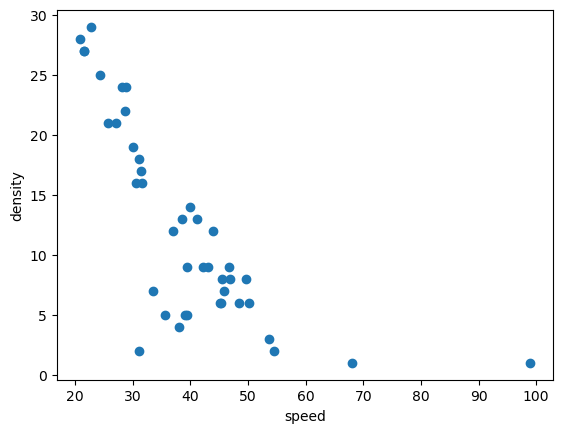

In [14]:
plt.scatter(df["speed"], df["density"])
plt.xlabel("speed")
plt.ylabel("density")
plt.show()


## Flow against density

Put density on the horizontal axis and flow on the vertical axis. Flow rises at the lower densities and comes down again at some higher densities. Do you think a straight line is suitable for the whole trend, including both the rising part and the falling part?


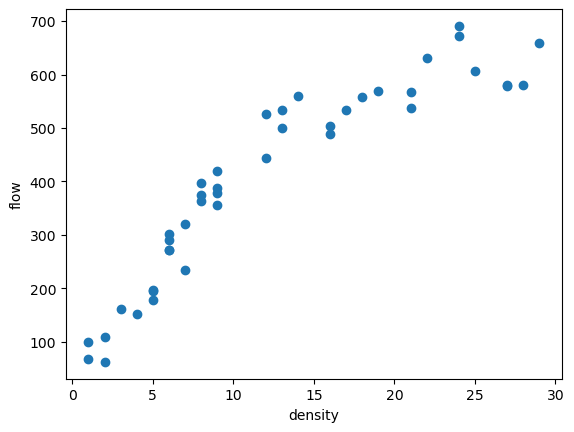

In [15]:
plt.scatter(df["density"], df["flow"])
plt.xlabel("density")
plt.ylabel("flow")
plt.show()


## Ask Colab to write the next cell

Paste this prompt into Colab's AI, generate the code in the empty cell, and run it.

> Use the existing DataFrame named df. Add a column slow that equals 1 when speed is below 30 and equals 0 otherwise. Print how many rows have slow equal to 1.

The count is 11. That count does not say whether flow rises and then falls. The figure in the previous cell is what shows the two sides.
